# 10 — Saving resources with time instead of space

Idle qubits are usually protected by more space: a larger distance,
or a denser storage code. The optimal interval protects them with time: the same code,
extracted less often. Two ways to price that, from the H2-1E regime grid (notebook 09):

- **qubits:** does the optimal interval at distance d beat back-to-back extraction at d + 2?
  If so, waiting replaces a distance step: (d+2)² − d² data qubits per logical qubit
  (rotated surface code; about twice that with ancillas);
- **operations:** per unit time the memory extracts Δt* times less often, so it runs Δt*
  times fewer two-qubit gates and measurements, which dominate a trapped-ion machine's cost
  (Quantinuum's HQC formula weights them; *interp.*).

**Setup (the regime grid of notebook 09; nothing new is simulated here).**
- Circuit: Stim's rotated surface-code memory circuit (H, 4 CX layers, H, measure-reset;
  7 layers per round), X basis, d = 3, 5, 7, decoded by PyMatching on the circuit's DEM.
- Noise: H2-1E emulator defaults, unscaled (p2 = 1.05×10⁻³); idle Z dephasing (linear +
  twirled quadratic) on every qubit, during each layer and during the wait (notebook 03).
- t_R is not published for H2: it is the x-axis, each value a hypothetical device.
- N = 60 rounds per run, so T = 60·Δt·t_R grows with Δt; R = −ln(1−2p_L)/(2T) assumes a
  constant rate per unit time. Per second = per round time / t_R.
- "Optimal interval" is the lowest sampled point of a 14-point Δt grid (1–256 rounds), not
  the fitted Δt*. About 400 failures per point.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
grid = json.loads(next((R / "regime" / "grid").glob("regime_*.json")).read_text())
rows = grid["rows"]
T_R = sorted({r["t_round"] for r in rows}); DS = sorted({r["d"] for r in rows})
cell = {(r["t_round"], r["d"]): r for r in rows}
def best(r):                            # lowest used rate and its interval
    return min((p["r"], p["dt"]) for p in r["points"] if p.get("used"))
print("calibration:", grid["calibration"]["source"][:90], "...")
print(f"{len(rows)} (t_R, d) cells; rounds per run {grid['setup']['rounds']}, "
      f"target {grid['setup']['target']} failures per point, max {grid['setup']['max_shots']:,} shots")

calibration: Quantinuum H2-1E emulator noise-model defaults, table dated 2025-07-16 (as used in the ori ...
39 (t_R, d) cells; rounds per run 60, target 400 failures per point, max 2,000,000 shots


In [3]:
# Study rates are per unit of round time (T counted in rounds); per second = / t_R.
print(f"{'t_R ms':>7}{'d':>3}{'b2b(d) /s':>11}{'opt(d) /s':>11}{'b2b(d+2) /s':>12}   {'optimal(d) beats b2b(d+2)?':<30}{'extractions':>12}")
for t in T_R:
    for d in DS[:-1]:
        a, b = cell.get((t, d)), cell.get((t, d + 2))
        if not (a and b):
            continue
        r_b2b, r_opt, r_next = (x / t for x in (a["points"][0]["r"], best(a)[0], b["points"][0]["r"]))
        verdict = f"yes: saves {(d + 2)**2 - d**2} data qubits" if r_opt < r_next else "no"
        print(f"{t*1e3:>7.1f}{d:>3}{r_b2b:>11.2e}{r_opt:>11.2e}{r_next:>12.2e}   {verdict:<30}"
              f"{a['dt_star_rounds']:>9.1f}x fewer")

 t_R ms  d  b2b(d) /s  opt(d) /s b2b(d+2) /s   optimal(d) beats b2b(d+2)?     extractions
    1.0  3   1.31e-01   2.91e-03    1.31e-02   yes: saves 16 data qubits          82.1x fewer
    1.0  5   1.31e-02   3.36e-04    9.49e-04   yes: saves 24 data qubits          65.5x fewer
    2.0  3   6.37e-02   2.83e-03    6.05e-03   yes: saves 16 data qubits          43.0x fewer
    2.0  5   6.05e-03   3.40e-04    5.07e-04   yes: saves 24 data qubits          32.2x fewer
    4.0  3   3.37e-02   2.71e-03    3.30e-03   yes: saves 16 data qubits          21.3x fewer
    4.0  5   3.30e-03   3.58e-04    2.58e-04   no                                 16.7x fewer
    7.0  3   1.80e-02   2.78e-03    1.81e-03   no                                 12.7x fewer
    7.0  5   1.81e-03   3.11e-04    1.49e-04   no                                  9.1x fewer
   10.0  3   1.31e-02   2.62e-03    1.36e-03   no                                  9.0x fewer
   10.0  5   1.36e-03   3.20e-04    9.82e-05   no               

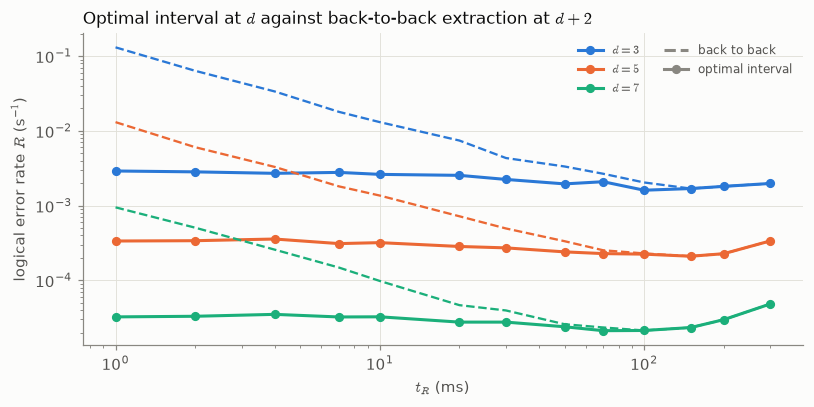

In [4]:
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for d in DS:
    ts = [t for t in T_R if (t, d) in cell]
    ax.plot([t * 1e3 for t in ts], [cell[(t, d)]["points"][0]["r"] / t for t in ts], "--", color=P.D_COLOR[d], lw=1.5)
    ax.plot([t * 1e3 for t in ts], [best(cell[(t, d)])[0] / t for t in ts], "o-", color=P.D_COLOR[d])
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$t_R$ (ms)"); ax.set_ylabel(r"logical error rate $R$ (s$^{-1}$)")
h = [Line2D([], [], color=P.D_COLOR[d], marker="o", label=P.dl(d)) for d in DS]
h += [Line2D([], [], color=P.MUTED, ls="--", label="back to back"),
      Line2D([], [], color=P.MUTED, marker="o", label="optimal interval")]
ax.legend(handles=h, fontsize=8, ncol=2)
ax.set_title(r"Optimal interval at $d$ against back-to-back extraction at $d + 2$", loc="left")
fig.tight_layout()
P.save(fig, "10_time_for_space_1")

**Reading.**
- *Measured:* for short rounds the optimal interval at distance d gives a lower logical
  error rate per second than back-to-back extraction at d + 2: up to t_R = 4 ms for
  d = 3 → 5, and up to 2 ms for d = 5 → 7. There, time replaces a distance step, saving
  (d+2)² − d² data qubits per idle logical qubit (16 and 24), with no change to the code.
  For longer rounds the gain is real but smaller than a distance step (notebook 09: ×2–12
  between 4 and 30 ms).
- *Measured:* in the same regime the memory extracts Δt* times less often, tens of times at
  t_R of a few ms, so its gate and measurement count per unit time falls by that factor.
- *Interp., the pitch:* combined with notebook 01 (most logical qubit time in sequential
  workloads is idle, in long stretches), the interval is a free knob acting on most of an
  application's space-time volume. Mis-setting it costs more as d grows (the paper's Γ_opt
  grows exponentially in α ∝ d), so it should be calibrated per device, which takes one
  calibration (notebook 05).
- *Boundary:* a full distance step is saved only for rounds of a few ms; any gain needs idle
  error per round well below p2. On H2 both depend on t_R, unknown until measured
  (notebook 09).